# MSM milling dataset: data loading and sensor availability

Multi-sensor and MTConnect milling anomaly dataset (3 machines). This notebook
1. finds every run and every file type per machine,
2. counts the labels,
3. separates controller variables from extra sensors, and
4. shows one labelled run per machine.

Run all cells from top to bottom, then save the notebook so the outputs stay in the file.
Set `DATA_DIR` below to the folder that contains `imi_vm20i`, `imi_vmx30ui`, `tmf_vf10` and `dataset_summary.xlsx`.

In [1]:
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import display

# Folder that holds the three machine folders and dataset_summary.xlsx
DATA_DIR = Path(os.environ.get("MSM_DATA_DIR", "Data"))
MACHINES = ["imi_vm20i", "imi_vmx30ui", "tmf_vf10"]
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

assert DATA_DIR.exists(), f"Data folder not found: {DATA_DIR.resolve()}"
print("Data folder:", DATA_DIR.resolve())

c:\Users\HP\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Data folder: C:\Users\HP\EL Sewedy University of Technology\3(1)\Machine Learning\Individual_Project_MachineLearning\Data


## 1. Runs and files

Each `datasetN` folder is one machining run. File roles are detected from the file-name suffix.

In [2]:
FILE_ROLES = {
    "acc": "_acc.csv",     # accelerometers (high frequency)
    "mtc": "_mtc.csv",     # MTConnect data (controller + integrated sensors)
    "ct": "_ct.csv",       # current transformer
    "s0": "_s0.wav",       # sound 0
    "s1": "_s1.wav",       # sound 1
    "s2": "_s2.wav",       # sound 2
    "label": "label.csv",  # labelled segments
    "nc": ".nc",           # NC program
    "video": ".mp4",       # video
}


def natural_key(name):
    digits = re.sub(r"\D", "", name)
    return int(digits) if digits else 0


def find_role(files, suffix):
    hits = [f for f in files if f.endswith(suffix)]
    return hits[0] if hits else None


rows = []
for m in MACHINES:
    run_dirs = [p for p in (DATA_DIR / m).iterdir() if p.is_dir()]
    for run_dir in sorted(run_dirs, key=lambda p: natural_key(p.name)):
        files = [f.name for f in run_dir.iterdir() if f.is_file()]
        row = {"machine": m, "run": run_dir.name, "path": str(run_dir)}
        for role, suffix in FILE_ROLES.items():
            row[role] = find_role(files, suffix)
        rows.append(row)

runs = pd.DataFrame(rows)
print("Total runs:", len(runs))

availability = runs.groupby("machine")[list(FILE_ROLES)].agg(lambda s: int(s.notna().sum()))
availability.insert(0, "runs", runs.groupby("machine").size())
availability = availability.loc[MACHINES]
display(availability)
availability.to_csv(OUT_DIR / "file_availability_by_machine.csv")

Total runs: 69


,runs,acc,mtc,ct,s0,s1,s2,label,nc,video
machine,,,,,,,,,,
imi_vm20i,37,37,37,0,37,37,37,37,37,37
imi_vmx30ui,19,0,19,0,19,0,19,19,19,19
tmf_vf10,13,0,13,13,13,0,13,13,0,0


## 2. Labels

`label.csv` lists the labelled segments of each run: 0 = normal, 1 = abnormal, 2 = tool defect (defective tool cutting normally).

In [3]:
LABEL_NAMES = {0: "normal", 1: "abnormal", 2: "tool defect"}


def load_label(run_path):
    return pd.read_csv(Path(run_path) / "label.csv")


frames = []
for r in runs.itertuples():
    if r.label is None:
        continue
    df = load_label(r.path)
    df.insert(0, "machine", r.machine)
    df.insert(1, "run", r.run)
    frames.append(df)

labels = pd.concat(frames, ignore_index=True)
labels["duration_s"] = labels["end"] - labels["start"]
print("Label columns:", list(labels.columns))
print("Segments with non-positive duration:", int((labels["duration_s"] <= 0).sum()))

counts = (
    labels.groupby(["machine", "label"])
    .agg(segments=("label", "size"), seconds=("duration_s", "sum"))
    .round(1)
)
display(counts)
counts.to_csv(OUT_DIR / "label_counts.csv")

total_s = labels["duration_s"].sum()
h, rem = divmod(int(round(total_s)), 3600)
mnt, s = divmod(rem, 60)
print(f"Labelled cutting time: {total_s:.1f} s = {h} h {mnt} m {s} s (the paper reports 4 h 44 m 38 s of cutting)")

share = labels.pivot_table(index="machine", columns="label", values="duration_s", aggfunc="sum", fill_value=0)
share = share.div(share.sum(axis=1), axis=0).round(3).loc[MACHINES]
share.columns = [LABEL_NAMES.get(c, c) for c in share.columns]
print("Share of labelled time per class:")
display(share)

Label columns: ['machine', 'run', 'start', 'end', 'label', 'direction', 'N', 'ap', 'ae', 'F', 'Z', 'D', 'Tool', 'Workpiece', 'duration_s']
Segments with non-positive duration: 0


segments  seconds
machine     label                   
imi_vm20i   0          1173   3662.0
            1           325   1394.0
            2            87    238.4
imi_vmx30ui 0           704   1526.5
            1           133    656.0
            2            90    184.7
tmf_vf10    0            56   9180.0
            1             7    236.7

Labelled cutting time: 17078.3 s = 4 h 44 m 38 s (the paper reports 4 h 44 m 38 s of cutting)
Share of labelled time per class:


,normal,abnormal,tool defect
machine,,,
imi_vm20i,0.692,0.263,0.045
imi_vmx30ui,0.645,0.277,0.078
tmf_vf10,0.975,0.025,0.000


## 3. Dataset summary file

In [4]:
summary = pd.read_excel(DATA_DIR / "dataset_summary.xlsx")
print(summary.shape, list(summary.columns))
display(summary.head())
print("Runs on disk:", len(runs), "| rows in summary:", len(summary))
display(summary.groupby("machine").size().rename("rows in summary").to_frame().join(
    runs.groupby("machine").size().rename("runs on disk")))

(69, 5) ['machine', 'dataset', 'Workpiece', 'Tool', 'Remark']


,machine,dataset,Workpiece,Tool,Remark
0,imi_vm20i,1,AA 6061,A*,NaN
1,imi_vm20i,2,AA 6061,B*,NaN
2,imi_vm20i,3,AISI 4140,D*,NaN
3,imi_vm20i,4,AISI 4140,E*,NaN
4,imi_vm20i,5,AA 6061,A,NaN


Runs on disk: 69 | rows in summary: 69


,rows in summary,runs on disk
machine,,
imi_vm20i,37,37
imi_vmx30ui,19,19
tmf_vf10,13,13


## 4. Columns of mtc.csv per machine

`mtc.csv` mixes controller variables with readings from external sensors that are integrated into MTConnect
(power meter, motor vibration sensors, temperature). Only the controller variables may be used by the deployed model.

In [5]:
# External sensors that arrive through MTConnect: power meter and per-motor vibration / displacement / temperature.
EXTERNAL_SENSOR = re.compile(r"^(energy|watt|[sxyz]m(apeak|arms|crest|vrms|disp|temp))$")


def run_file(run_path, suffix):
    f = find_role([p.name for p in Path(run_path).iterdir()], suffix)
    return None if f is None else Path(run_path) / f


def load_mtc(run_path):
    return pd.read_csv(run_file(run_path, "_mtc.csv"))


mtc_cols = {}
for m in MACHINES:
    first_run = runs[(runs.machine == m) & runs.mtc.notna()].iloc[0]
    mtc_cols[m] = list(load_mtc(first_run.path).columns)

col_rows = []
for m, cols in mtc_cols.items():
    for c in cols:
        kind = "external sensor" if EXTERNAL_SENSOR.match(c) else "controller / machine state"
        col_rows.append({"machine": m, "column": c, "kind": kind})
col_table = pd.DataFrame(col_rows)
col_table.to_csv(OUT_DIR / "mtc_columns_by_machine.csv", index=False)
display(col_table.groupby(["machine", "kind"]).size().unstack(fill_value=0).loc[MACHINES])

common_by_name = set.intersection(*[set(c) for c in mtc_cols.values()])
print("Columns with the same name on all three machines:", sorted(common_by_name))

kind,controller / machine state,external sensor
machine,,
imi_vm20i,30,22
imi_vmx30ui,34,22
tmf_vf10,21,0


Columns with the same name on all three machines: ['avail', 'time']


## 5. Controller variables matched by meaning

Only `time` and `avail` share a name across the three controllers, so the shared set is defined by meaning.
Mappings marked "to confirm" must be checked against the MTConnect device models
(`imi_vm20i.xml`, `imi_vmx30ui.xml`, `tmf_vf10.xml`).

In [6]:
def per_machine(vm20i, vmx30ui, vf10):
    return {"imi_vm20i": vm20i, "imi_vmx30ui": vmx30ui, "tmf_vf10": vf10}


COMMON_CONTROLLER = {
    "time stamp":        per_machine("time", "time", "time"),
    "availability":      per_machine("avail", "avail", "avail"),
    "emergency stop":    per_machine("EStop_State", "EStop_State", "estop"),
    "execution state":   per_machine("Execution", "Execution", "execution"),
    "controller mode":   per_machine(["Controller_Mode", "Machine_Mode"], ["Controller_Mode", "Machine_Mode"], "mode"),
    "block number":      per_machine("Block_Number", "Block_Number", "block_num"),
    "part count":        per_machine("Part_Count", "Part_Count", "part_count"),
    "running program":   per_machine("Program_Name_Running", "Program_Name_Running", "program"),
    "tool number":       per_machine("Current_Tool", "Current_Tool", "tool_num"),
    "spindle speed":     per_machine("Spindle_Speed", "Spindle_Speed", "s_speed"),
    "spindle load":      per_machine("S_Axis_Load", "S_Axis_Load", "s_load"),
    "x position":        per_machine("X_Position", "X_Position", ["xpm", "xpw"]),
    "y position":        per_machine("Y_Position", "Y_Position", ["ypm", "ypw"]),
    "z position":        per_machine("Z_Position", "Z_Position", ["zpm", "zpw"]),
    "asset change/removal": per_machine(["dev_asset_chg", "dev_asset_rem"], ["dev_asset_chg", "dev_asset_rem"],
                                        ["vf10_50_asset_chg", "vf10_50_asset_rem"]),
    "timers":            per_machine(["Machine_Time", "Spindle_Time", "Program_Runtime_Seconds"],
                                     ["Machine_Time", "Spindle_Time", "Program_Runtime_Seconds"],
                                     ["motion_time", "last_cycle_time"]),
}

LAB_ONLY_CONTROLLER = {
    "feed rate, rapid speed": per_machine(["Feed_Rate", "Rapid_Speed"], ["Feed_Rate", "Rapid_Speed"], None),
    "overrides":              per_machine(["Feed_Override", "Spindle_Override", "Rapid_Override"],
                                          ["Feed_Override", "Spindle_Override", "Rapid_Override"], None),
    "x, y, z axis load":      per_machine(["X_Axis_Load", "Y_Axis_Load", "Z_Axis_Load"],
                                          ["X_Axis_Load", "Y_Axis_Load", "Z_Axis_Load"], None),
    "a, c axis load and position": per_machine(None, ["A_Axis_Load", "C_Axis_Load", "A_Position", "C_Position"], None),
}

TO_CONFIRM = {"controller mode", "x position", "y position", "z position", "timers"}


def presence(mapping):
    rows = []
    for meaning, pm in mapping.items():
        row = {"meaning": meaning}
        for m in MACHINES:
            names = pm.get(m)
            if names is None:
                row[m] = "none"
                continue
            names = [names] if isinstance(names, str) else names
            missing = [n for n in names if n not in mtc_cols[m]]
            row[m] = ", ".join(names) + (f"  <-- NOT FOUND in file: {missing}" if missing else "")
        row["in all three"] = all(pm.get(m) is not None for m in MACHINES)
        row["to confirm"] = meaning in TO_CONFIRM
        rows.append(row)
    return pd.DataFrame(rows)


controller_table = pd.concat([presence(COMMON_CONTROLLER), presence(LAB_ONLY_CONTROLLER)], ignore_index=True)
pd.set_option("display.max_colwidth", 80)
display(controller_table)
controller_table.to_csv(OUT_DIR / "controller_variables_by_meaning.csv", index=False)

,meaning,imi_vm20i,imi_vmx30ui,tmf_vf10,in all three,to confirm
0,time stamp,time,time,time,True,False
1,availability,avail,avail,avail,True,False
2,emergency stop,EStop_State,EStop_State,estop,True,False
3,execution state,Execution,Execution,execution,True,False
4,controller mode,"Controller_Mode, Machine_Mode","Controller_Mode, Machine_Mode",mode,True,True
5,block number,Block_Number,Block_Number,block_num,True,False
6,part count,Part_Count,Part_Count,part_count,True,False
7,running program,Program_Name_Running,Program_Name_Running,program,True,False
8,tool number,Current_Tool,Current_Tool,tool_num,True,False
9,spindle speed,Spindle_Speed,Spindle_Speed,s_speed,True,False


## 6. Extra sensors (teacher side)

In [7]:
def has_cols(m, pattern):
    return any(re.search(pattern, c) for c in mtc_cols[m])


sensor_rows = [
    ("Sound0, USB microphone (s0.wav)",        lambda m: availability.loc[m, "s0"] > 0),
    ("Sound1, internal near spindle (s1.wav)", lambda m: availability.loc[m, "s1"] > 0),
    ("Sound2, internal base column (s2.wav)",  lambda m: availability.loc[m, "s2"] > 0),
    ("Accelerometers (acc.csv)",               lambda m: availability.loc[m, "acc"] > 0),
    ("Current transformer (ct.csv)",           lambda m: availability.loc[m, "ct"] > 0),
    ("Motor vibration columns in mtc.csv",     lambda m: has_cols(m, r"^[sxyz]m(apeak|arms|crest|vrms)$")),
    ("Motor displacement columns in mtc.csv",  lambda m: has_cols(m, r"^[sxyz]mdisp$")),
    ("Motor temperature columns in mtc.csv",   lambda m: has_cols(m, r"^[sxyz]mtemp$")),
    ("Power meter columns in mtc.csv",         lambda m: has_cols(m, r"^(watt|energy)$")),
]
sensor_table = pd.DataFrame(
    {name: {m: ("yes" if bool(fn(m)) else "no") for m in MACHINES} for name, fn in sensor_rows}
).T
display(sensor_table)
sensor_table.to_csv(OUT_DIR / "extra_sensor_availability.csv")

,imi_vm20i,imi_vmx30ui,tmf_vf10
"Sound0, USB microphone (s0.wav)",yes,yes,yes
"Sound1, internal near spindle (s1.wav)",yes,no,no
"Sound2, internal base column (s2.wav)",yes,yes,yes
Accelerometers (acc.csv),yes,no,no
Current transformer (ct.csv),no,no,yes
Motor vibration columns in mtc.csv,yes,yes,no
Motor displacement columns in mtc.csv,yes,no,no
Motor temperature columns in mtc.csv,no,yes,no
Power meter columns in mtc.csv,yes,yes,no


## 7. Loaders for the other signals

In [8]:
def load_wav(run_path, channel="s0"):
    """Memory-mapped read, so a long recording is not copied into RAM."""
    sr, data = wavfile.read(run_file(run_path, f"_{channel}.wav"), mmap=True)
    return sr, data


def load_acc(run_path, nrows=None):
    return pd.read_csv(run_file(run_path, "_acc.csv"), nrows=nrows)


def load_ct(run_path):
    return pd.read_csv(run_file(run_path, "_ct.csv"))


def rms_envelope(data, sr, win_s=0.1, windows_per_block=2000):
    """RMS of the signal in consecutive windows of win_s seconds."""
    win = int(sr * win_s)
    n = len(data) // win
    out = np.empty(n, dtype=np.float32)
    for i in range(0, n, windows_per_block):
        j = min(i + windows_per_block, n)
        block = np.asarray(data[i * win:j * win], dtype=np.float32).reshape(-1, win)
        out[i:j] = np.sqrt((block ** 2).mean(axis=1))
    return np.arange(n) * win_s, out


info_rows = []
for m in MACHINES:
    r = runs[(runs.machine == m) & runs.s0.notna()].iloc[0]
    sr, wav = load_wav(r.path, "s0")
    info = {"machine": m, "run": r.run, "wav_rate_hz": sr, "wav_channels": 1 if wav.ndim == 1 else wav.shape[1],
            "wav_seconds": round(len(wav) / sr, 1)}
    if pd.notna(r.acc):
        acc = load_acc(r.path, nrows=1000)
        info["acc_step_us"] = round(float(acc["time"].diff().median()) * 1e6, 1)
        info["acc_columns"] = ", ".join(acc.columns)
    if pd.notna(r.ct):
        ct = load_ct(r.path)
        info["ct_rows"] = len(ct)
        info["ct_step_s"] = round(float(ct["time"].diff().median()), 2) if len(ct) > 1 else None
    info["mtc_rows"] = len(load_mtc(r.path))
    info_rows.append(info)
display(pd.DataFrame(info_rows).set_index("machine"))

,run,wav_rate_hz,wav_channels,wav_seconds,acc_step_us,acc_columns,mtc_rows,ct_rows,ct_step_s
machine,,,,,,,,,
imi_vm20i,dataset1,48000,1,111.8,19.5,"time, acc0, acc1",750,NaN,NaN
imi_vmx30ui,dataset1,48000,1,180.0,NaN,NaN,800,NaN,NaN
tmf_vf10,dataset1,48000,1,1003.4,NaN,NaN,2769,101.0,10.0


## 8. One run per machine with its labels

Blue = normal, red = abnormal, orange = tool defect. Top: sound envelope. Middle and bottom: controller spindle speed and spindle load.

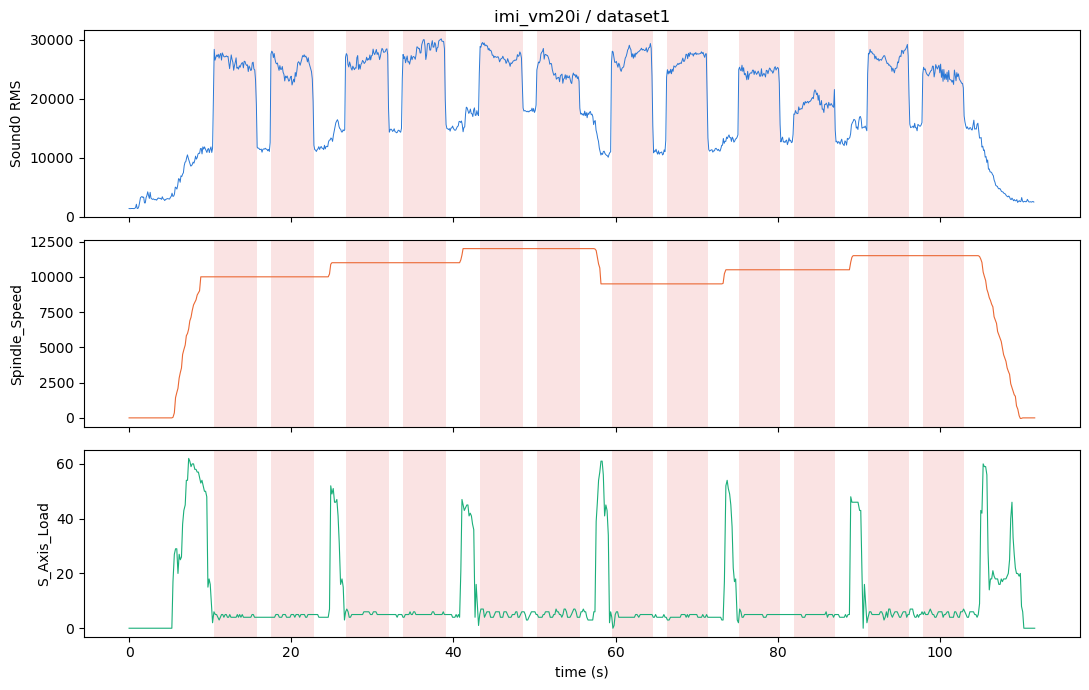

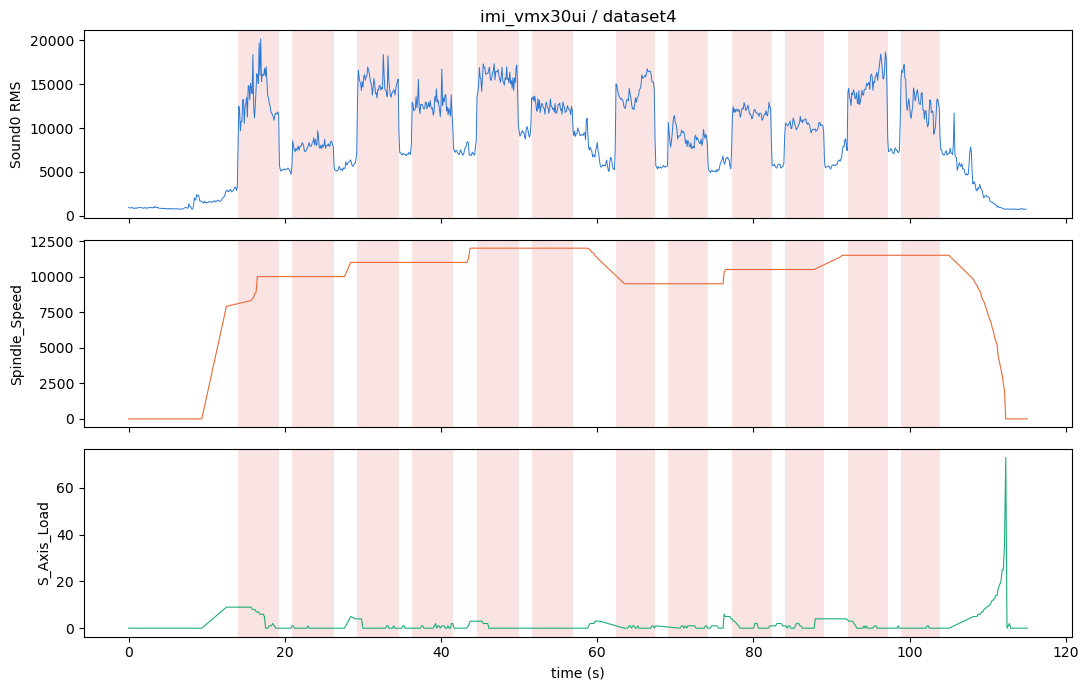

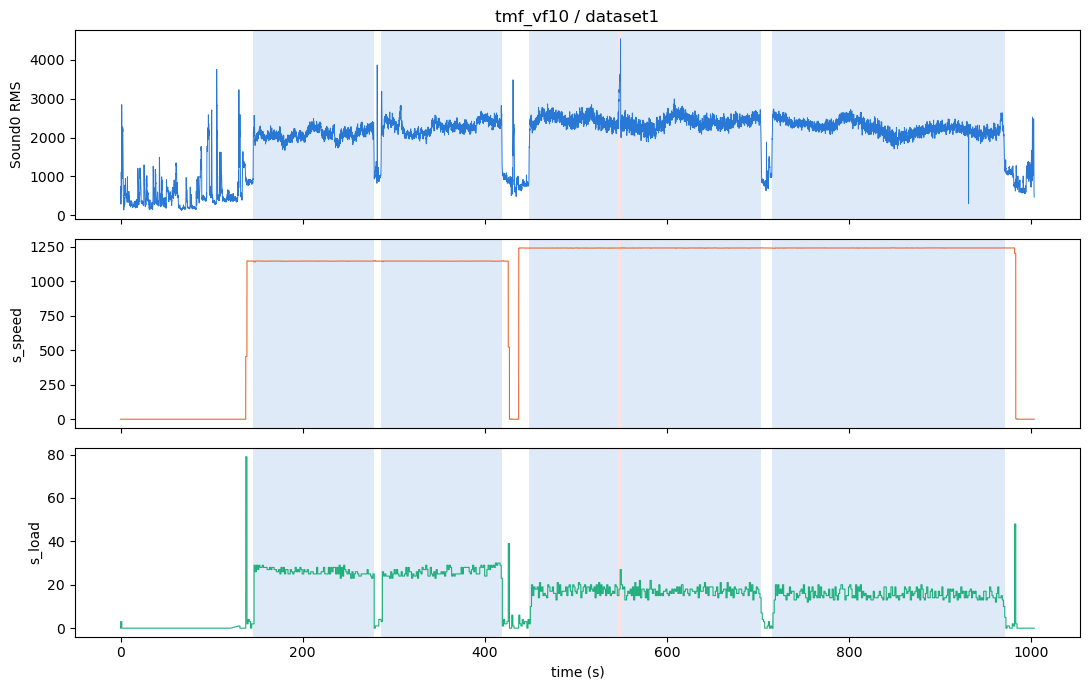

In [9]:
SEG_COLORS = {0: "#2a78d6", 1: "#e34948", 2: "#eb6834"}


def pick_run(m):
    cand = runs[(runs.machine == m) & runs.mtc.notna() & runs.s0.notna()]
    with_abnormal = labels[(labels.machine == m) & (labels.label == 1)]["run"].unique()
    preferred = cand[cand.run.isin(with_abnormal)]
    return (preferred if len(preferred) else cand).iloc[0]


def plot_run(r):
    speed_col = COMMON_CONTROLLER["spindle speed"][r.machine]
    load_col = COMMON_CONTROLLER["spindle load"][r.machine]
    mtc = load_mtc(r.path)
    lab = load_label(r.path)
    sr, wav = load_wav(r.path, "s0")
    t_env, env = rms_envelope(wav, sr)

    fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
    axes[0].plot(t_env, env, lw=0.7, color="#2a78d6")
    axes[0].set_ylabel("Sound0 RMS")
    axes[1].plot(mtc["time"], mtc[speed_col], lw=0.8, color="#eb6834")
    axes[1].set_ylabel(f"{speed_col}")
    axes[2].plot(mtc["time"], mtc[load_col], lw=0.8, color="#1baf7a")
    axes[2].set_ylabel(f"{load_col}")
    axes[2].set_xlabel("time (s)")
    for ax in axes:
        for seg in lab.itertuples():
            ax.axvspan(seg.start, seg.end, color=SEG_COLORS.get(seg.label, "gray"), alpha=0.15, lw=0)
    axes[0].set_title(f"{r.machine} / {r.run}")
    plt.tight_layout()
    plt.show()


for m in MACHINES:
    plot_run(pick_run(m))

## 9. Saved tables

In [10]:
for p in sorted(OUT_DIR.iterdir()):
    print(p.name, "|", p.stat().st_size, "bytes")

controller_variables_by_meaning.csv | 1627 bytes
extra_sensor_availability.csv | 448 bytes
file_availability_by_machine.csv | 165 bytes
label_counts.csv | 220 bytes
mtc_columns_by_machine.csv | 5855 bytes


## Notes

- The label counts above come from `label.csv` in each run folder, not from `dataset_summary.xlsx`.
- `time` in `mtc.csv`, `acc.csv`, `ct.csv` and the label start/end are in seconds on a common zero per run; the sound envelope uses sample index divided by the sampling rate.
- External-sensor columns inside `mtc.csv` (power, motor vibration, displacement, temperature) are excluded from the controller-only student.